# 05 · Benchmark de latencia, monitoreo y auditoría — Sprint 2
> **Datos 100 % sintéticos.** AURORA SCORE y Vertex Financial Group son un caso ficticio con fines académicos (SCY1102, Duoc UC). Ejecutar antes `python src/pipeline.py`.

Tarjetas AUR-16, AUR-17, AUR-18. RNF-01: decisión en menos de 8 s en el percentil 95.

In [1]:
import sys, json
from pathlib import Path
RAIZ = Path.cwd().parent
sys.path.insert(0, str(RAIZ / "src"))
import pandas as pd
from IPython.display import Image, display
pd.set_option("display.max_columns", 30); pd.set_option("display.width", 160)
REP = RAIZ / "reports"; FIG = REP / "figures"
leer = lambda n: json.loads((REP / n).read_text(encoding="utf-8"))

In [2]:
l = leer('latencia_resumen.json')
{k: v for k, v in l.items() if not isinstance(v, (dict, list))}

{'n_solicitudes': 2000,
 'p50_ms': 984.9,
 'p95_ms': 1815.7,
 'p99_ms': 1965.9,
 'max_ms': 2422.3,
 'limite_p95_ms': 8000,
 'cumple_rnf01': True,
 'holgura_p95_ms': 6184.3,
 'pct_timeout_terceros': 6.95}

In [3]:
pd.DataFrame({'p95_ms': l['p95_por_componente_ms'], 'media_ms': l['medio_por_componente_ms']})

,p95_ms,media_ms
1_recepcion,260.47,132.20
2_identidad,0.02,0.01
3_feature_store,155.75,71.09
4_variables_al_vuelo,1.44,1.37
5_terceros,1500.00,720.86
6_inferencia,5.04,4.81
7_reglas,0.13,0.12
8_shap,5.69,5.53
9_respuesta,267.99,133.98


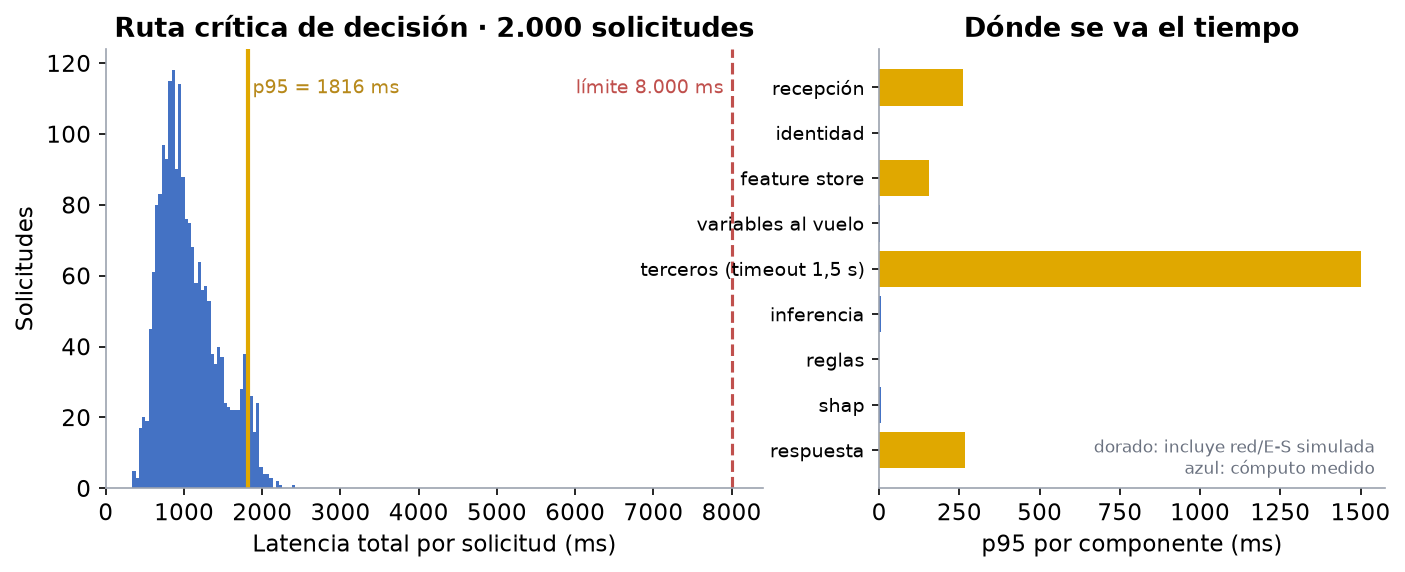

In [4]:
display(Image(FIG / '08_latencia.png', width=900))

## Monitoreo de drift (RF-11)

In [5]:
mo = leer('monitoreo_resumen.json')
print('PSI del score:', mo['psi_score_total'], '· KS del score:', mo['ks_score_total'], '·', mo['variables_por_estado'])
pd.DataFrame(mo['score_mensual'])

PSI del score: 0.0029 · KS del score: 0.0129 · {'estable': 43}


,mes,psi_score,estado,tasa_aprobacion
0,2025-10,0.0047,estable,0.7494
1,2025-11,0.0040,estable,0.7478
2,2025-12,0.0055,estable,0.7456


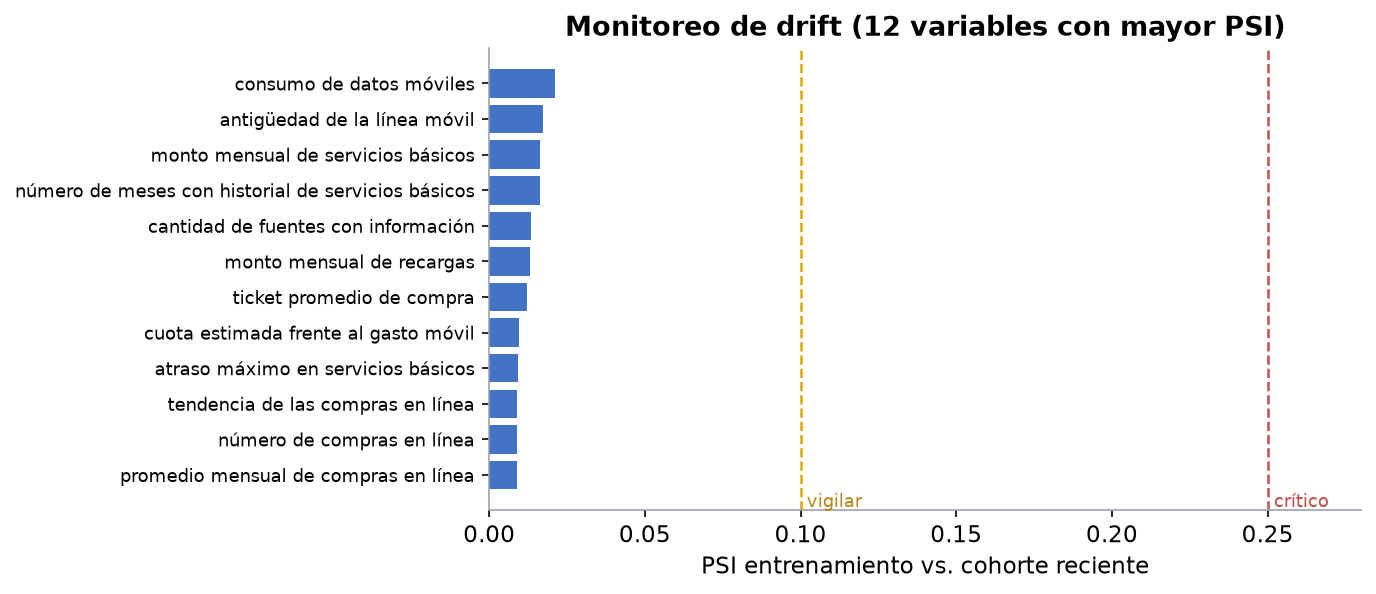

In [6]:
display(Image(FIG / '09_drift_psi.png', width=750))

## Registro de auditoría inmutable (RF-12)

In [7]:
leer('auditoria_integridad.json')

{'registros_escritos': 12000,
 'verificacion_original': {'integro': True, 'registros': 12000},
 'prueba_manipulacion_linea_500': {'integro': False,
  'primera_linea_alterada': 500}}

In [8]:
print((RAIZ / 'data/audit/decisiones.jsonl').open(encoding='utf-8').readline()[:600])

{"registro": {"solicitud_id": 30001, "pais": "PE", "fecha": "2025-10-01", "version_modelo": "v2-mitigado", "sha256_modelo": "3d3fe1b192eeb225", "pd": 0.03872, "umbral": 0.13, "decision": "aprobado"}, "hash_anterior": "0000000000000000000000000000000000000000000000000000000000000000", "hash": "a93eb8469ca8b1aca62e81067e26eb8601c7857ca001f8ba39f508eb51552a61"}

